# 🔧 MOD-07 — Imputación y Control de Calidad

**Proyecto:** Medición del Impacto de la Variabilidad Climática en Producción Arrocera mediante Aprendizaje Automático  
**Maestría en Ciencia de Datos — Pontificia Universidad Javeriana Cali**  
**Directora:** Yady Tatiana Solano Correa  
**Equipo:** Rafael Del Castillo Pavajeau | Wilson Briñez Bermúdez | Martín Naranjo Escobar

---

## 📋 Descripción del módulo

Este módulo resuelve los valores faltantes del **Dataset Maestro Consolidado** (MOD-06) aplicando estrategias de imputación diferenciadas por porcentaje de nulos. La versión **v2.0** extiende el KNN con k adaptativo al rango completo 0%–80%, eliminando la mediana global como método primario para el rango 51%–80% y mejorando la coherencia climática regional de las imputaciones.

Adicionalmente calcula **variables de varianza intra-semestral** (`*_var`) para cada métrica climática, capturando la variabilidad dentro del semestre como feature adicional.

### Métodos de imputación aplicados (v2.0)

| Rango de nulos | Método | Parámetro |
|---|---|---|
| 0% | Sin imputación | — |
| 1%–80% | **KNN k=10 adaptativo por Departamento** | `UMBRAL_KNN=0.80` |
| > 80% | Eliminación de columna | `UMBRAL_EXCLUIR=0.80` |
| 100% (`prec_*`) | Exclusión total desde el inicio | — |
| Residual post-KNN | Mediana global (último recurso) | — |

El **k adaptativo** garantiza que nunca se pidan más vecinos de los disponibles en el grupo: `k_real = min(10, n_validos_en_depto - 1)`, con k mínimo garantizado de 3.

---

## 📂 Estructura de archivos

```
Proyecto_Aplicado_II/
├── notebooks/
│   └── MOD07_imputacion_calidad.ipynb      ← Este archivo
└── data/
    └── master/
        ├── A1_DF_Consolidado.parquet        ← Entrada desde MOD-06
        ├── A2_DF_Imputado.parquet           ← Salida principal → MOD-08
        ├── A2_DF_Imputado.xlsx              ← Inspección visual
        ├── A2_Reporte_Imputacion.xlsx       ← Trazabilidad + varianzas
        └── A2_Dashboard_Imputacion.png      ← Dashboard 9 paneles
```

---

## ⬅️ Entradas / ➡️ Salidas

| Tipo | Archivo | Origen |
|------|---------|--------|
| Entrada | `data/master/A1_DF_Consolidado.parquet` | MOD-06 |
| Salida 1 | `data/master/A2_DF_Imputado.parquet` | Este módulo |
| Salida 2 | `data/master/A2_DF_Imputado.xlsx` | Este módulo |
| Salida 3 | `data/master/A2_Reporte_Imputacion.xlsx` | Este módulo |
| Salida 4 | `data/master/A2_Dashboard_Imputacion.png` | Este módulo |

---

## 🔗 Dependencias entre módulos

```
MOD-06 → A1_DF_Consolidado.parquet
         └─→ [MOD-07] Imputación y Control de Calidad
                  └─→ A2_DF_Imputado.parquet → MOD-08
```

> **Arquitectura v2.0:** Usa `cod_divipola` como llave universal. Requiere **MOD-00** ejecutado.

---

## 🔄 Flujo de ejecución

| # | Celda | Descripción |
|---|-------|-------------|
| 1 | Entorno | Instalación (`sklearn`, `pyarrow`) e imports |
| 2 | Rutas y parámetros | `RUTA_BASE`, parámetros KNN v2.0: `KNN_K=10`, `UMBRAL_KNN=0.80`, `UMBRAL_EXCLUIR=0.80` |
| 3 | Funciones | `imputar_bloque_knn()` k adaptativo, `imputar_mediana_global()` solo último recurso, `construir_reporte_imputacion()` |
| 4 | Cargar dataset | Carga `A1_DF_Consolidado.parquet`, identifica bloques climáticos y diagnóstico de nulos antes de imputación |
| 5 | Paso 1 | Elimina `prec_*` (100% nulos) y clasifica columnas: 0–80% → KNN, >80% → eliminar |
| 6 | Paso 2 | KNN k=10 adaptativo por departamento sobre 1%–80% nulos. Detalle del k real usado por grupo |
| 7 | Paso 3 | Consolida trazabilidad y muestra diagnóstico post-imputación con tabla comparativa v1.0 vs v2.0 |
| 8 | Paso 4 | Calcula variables de varianza intra-semestral `*_var` (varianza m1..m6) por bloque climático |
| 9 | Reorganizar | Ordena columnas por bloques y optimiza tipos a `float32` |
| 10 | Dashboard | Genera `A2_Dashboard_Imputacion.png`: nulos antes/después, métodos, boxplots varianza, evolución temperatura, scatter varianza vs rendimiento |
| 11 | Reporte y guardar | Exporta reporte de trazabilidad Excel y dataset imputado Parquet + Excel |
| 12 | Resumen final | Métodos aplicados, variables `*_var` creadas por bloque e inventario final del dataset |


---
## ⚙️ CELDA 1 — Instalación de dependencias y configuración de entorno

Instala `openpyxl`, `pyarrow` y `scikit-learn`. Importa `KNNImputer` de `sklearn.impute` y todos los módulos necesarios para el proceso de imputación.

In [1]:
# ============================================================
# MOD-07 — Imputación y Control de Calidad
# Proyecto: Impacto Variabilidad Climática en Producción Arrocera
# Versión  : 1.0
# Entrada  : data/master/A1_DF_Consolidado.parquet  (MOD-06)
# Salida   : data/master/A2_DF_Imputado.parquet / .xlsx
# ============================================================
# Métodos de imputación aplicados:
#   1. KNN  (k=5, por departamento)  — variables con <50% nulos
#   2. Mediana global                — respaldo cuando KNN falla
#   3. Eliminación de filas          — variables con >80% nulos
#   Los Ind_lluvia (prec_*) se EXCLUYEN completamente (100% nulos)
# ============================================================
!pip install openpyxl pyarrow scikit-learn -q

import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.impute import KNNImputer
import pyarrow.parquet as pq
warnings.filterwarnings('ignore')

print('✅ Librerías cargadas')


✅ Librerías cargadas


---
## 📁 CELDA 2 — Configuración de rutas y parámetros

Detecta `RUTA_BASE` automáticamente en Google Drive. Define archivos de entrada/salida y parámetros clave de imputación v2.0: `KNN_K=10` (mejorado de 5 a 10), `UMBRAL_KNN=0.80` (extendido de 50% a 80%) y el prefijo `prec_` para exclusión total.

In [2]:
# ============================================================
# CONFIGURACION DE RUTAS — MOD-07 v2.0
# ============================================================
# Cambio clave v2.0:
#   KNN_K mejorado : 5 -> 10 (mas vecinos = imputacion mas estable)
#   Umbral KNN     : 50% -> 80% (KNN cubre ahora el rango 51-80% nulos)
#   Mediana global : ya NO se aplica al rango 51-80% (reemplazado por KNN)
#   Mediana global : solo queda como ultimo recurso post-KNN
# ============================================================

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
    print('Google Drive montado')
else:
    print('Google Drive ya montado')

# Deteccion automatica de RUTA_BASE
ARCHIVO_ANCLA = 'A1_DF_Consolidado.parquet'
RUTA_BASE     = None

print()
print('Buscando carpeta del proyecto...')
for dirpath, dirnames, filenames in os.walk('/content/drive/MyDrive'):
    depth = dirpath.replace('/content/drive/MyDrive', '').count(os.sep)
    if depth > 5:
        dirnames.clear()
        continue
    if ARCHIVO_ANCLA in filenames:
        candidate = os.path.dirname(os.path.dirname(dirpath))
        if os.path.isdir(os.path.join(candidate, 'data', 'master')):
            RUTA_BASE = candidate
            print(f'   Proyecto en: {RUTA_BASE}')
            break

if RUTA_BASE is None:
    RUTA_BASE = '/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II'
    print(f'   No encontrado. Usando: {RUTA_BASE}')

RUTA_MASTER    = os.path.join(RUTA_BASE, 'data', 'master')
RUTA_PROCESSED = os.path.join(RUTA_BASE, 'data', 'processed')
os.makedirs(RUTA_MASTER, exist_ok=True)

ENTRADA_CONSOLIDADO = os.path.join(RUTA_MASTER, 'A1_DF_Consolidado.parquet')
SALIDA_IMPUTADO     = os.path.join(RUTA_MASTER, 'A2_DF_Imputado.parquet')
SALIDA_IMPUTADO_XLS = os.path.join(RUTA_MASTER, 'A2_DF_Imputado.xlsx')
SALIDA_REPORTE_XLS  = os.path.join(RUTA_MASTER, 'A2_Reporte_Imputacion.xlsx')

# ── Parametros de imputacion v2.0 ────────────────────────────
# k=10: con departamentos arroceros que tienen 50-150 filas,
# k=10 garantiza suficientes vecinos para estabilizar la imputacion
# sin perder la señal climatica regional.
KNN_K          = 10     # mejorado de 5 a 10

# Umbral KNN extendido a 80%: KNN ahora cubre tanto el rango
# 0-50% (antes) como el rango 51-80% (nuevo). La mediana global
# ya NO se aplica en el rango 51-80%, solo como ultimo recurso
# post-KNN cuando un grupo no tiene ningun vecino valido.
UMBRAL_KNN     = 0.80   # extendido: antes 0.50, ahora 0.80
UMBRAL_EXCLUIR = 0.80   # eliminar columna si > 80% nulos (sin cambio)

COLS_JOIN      = ['Periodo', 'Departamento', 'Municipio']

BLOQUES = {
    'Temperatura'  : 'temperatura_',
    'Precipitacion': 'precipitacion_',
    'Radiacion'    : 'radiacion_',
    'Humedad'      : 'hr_',
}
PREFIJO_EXCLUIR = 'prec_'

if not os.path.exists(ENTRADA_CONSOLIDADO):
    raise FileNotFoundError(
        'No se encontro A1_DF_Consolidado.parquet.\n'
        'Ejecuta MOD-06 antes de continuar.'
    )

print()
print('Rutas:')
print(f'   Master  -> {RUTA_MASTER}')
print(f'   Entrada -> {os.path.basename(ENTRADA_CONSOLIDADO)} OK')
print()
print('Parametros de imputacion v2.0:')
print(f'   KNN K          : {KNN_K} vecinos  (antes: 5)')
print(f'   Umbral KNN     : <= {UMBRAL_KNN*100:.0f}% nulos  (antes: <= 50%)')
print(f'   Umbral excluir : >  {UMBRAL_EXCLUIR*100:.0f}% nulos  (sin cambio)')
print(f'   Mediana global : solo ultimo recurso post-KNN  (antes: 51-80%)')
print(f'   prec_*         : EXCLUIDOS (100% nulos)')


Mounted at /content/drive
Google Drive montado

Buscando carpeta del proyecto...
   Proyecto en: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II

Rutas:
   Master  -> /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master
   Entrada -> A1_DF_Consolidado.parquet OK

Parametros de imputacion v2.0:
   KNN K          : 10 vecinos  (antes: 5)
   Umbral KNN     : <= 80% nulos  (antes: <= 50%)
   Umbral excluir : >  80% nulos  (sin cambio)
   Mediana global : solo ultimo recurso post-KNN  (antes: 51-80%)
   prec_*         : EXCLUIDOS (100% nulos)


---
## 🔧 CELDA 3 — Funciones utilitarias

Define `reporte_nulos()`, `imputar_bloque_knn()` con k adaptativo `min(k, n_validos-1)` y k mínimo garantizado=3, `imputar_mediana_global()` (solo último recurso en v2.0) y `construir_reporte_imputacion()` para trazabilidad completa por columna.

In [3]:
# ============================================================
# FUNCIONES UTILITARIAS — MOD-07 v2.0
# Mejora en imputar_bloque_knn:
#   - k adaptativo: usa min(KNN_K, n_validos-1) por grupo
#     para evitar que grupos pequenos fallen silenciosamente
#   - K minimo garantizado: al menos k=3 si hay datos suficientes
#   - Reporte detallado: muestra k real usado por departamento
# ============================================================

def reporte_nulos(df, cols, titulo=''):
    nulos = df[cols].isna().sum()
    pct   = nulos / len(df) * 100
    tbl   = pd.DataFrame({'columna': cols,
                          'nulos': nulos.values,
                          'pct_nulos': pct.values.round(2)})
    tbl = tbl[tbl['nulos'] > 0].sort_values('pct_nulos', ascending=False)
    if titulo:
        print(f'\n{titulo}')
    return tbl


def imputar_bloque_knn(df, cols, k=10, grupo_col='Departamento'):
    '''
    KNN Imputer por grupo (departamento) con k adaptativo.

    Mejoras v2.0 respecto a v1.0:
    ──────────────────────────────
    1. k ADAPTATIVO por grupo:
       Usa min(k, n_validos - 1) para cada departamento.
       Si un departamento tiene 12 filas validas y k=10,
       usa k=10. Si tiene 6 filas validas, usa k=5.
       Esto evita errores silenciosos cuando el grupo es pequeno.

    2. k MINIMO garantizado = 3:
       Si el grupo tiene al menos 4 filas validas, aplica KNN
       con k=3 en lugar de caer a mediana. Esto preserva mejor
       la estructura de correlacion climatica regional.

    3. REPORTE por departamento:
       Muestra el k real usado en cada grupo para trazabilidad.

    4. Cobertura extendida al rango 51-80%:
       El mismo metodo ahora imputa columnas con hasta 80% nulos,
       reemplazando la mediana global en ese rango.

    Flujo de decision por grupo:
      n_validos >= 4  -> KNN con k = min(k_param, n_validos-1)
      n_validos 1-3   -> Mediana del grupo (KNN inestable con < 4 puntos)
      n_validos = 0   -> Mediana global (ultimo recurso)

    Nulos residuales post-loop -> Mediana global (ultimo recurso).
    '''
    K_MINIMO = 3   # k minimo para aplicar KNN (requiere >= K_MINIMO+1 validos)

    df_out = df.copy()
    traza  = {}
    grupos = df[grupo_col].unique() if grupo_col in df.columns else ['_todo']

    for col in cols:
        n_nulos_orig = df_out[col].isna().sum()
        if n_nulos_orig == 0:
            traza[col] = {'metodo': 'sin_imputacion', 'n_imputados': 0,
                          'detalle_grupos': {}}
            continue

        imputados_total = 0
        detalle_grupos  = {}

        for grp in grupos:
            if grupo_col in df_out.columns:
                mask_grp = df_out[grupo_col] == grp
            else:
                mask_grp = pd.Series([True]*len(df_out), index=df_out.index)

            idx_grp     = df_out[mask_grp].index
            sub         = df_out.loc[idx_grp, cols].copy()
            n_nulos_grp = sub[col].isna().sum()

            if n_nulos_grp == 0:
                continue

            n_validos = sub[col].notna().sum()

            if n_validos >= K_MINIMO + 1:
                # KNN con k adaptativo
                k_real = min(k, n_validos - 1)
                imputer = KNNImputer(
                    n_neighbors=k_real,
                    weights='distance'
                )
                try:
                    sub_imp = imputer.fit_transform(sub.values)
                    df_out.loc[idx_grp, cols] = sub_imp
                    imputados_total += n_nulos_grp
                    detalle_grupos[str(grp)] = {
                        'metodo': f'KNN_k{k_real}',
                        'n_validos': int(n_validos),
                        'n_imputados': int(n_nulos_grp)
                    }
                except Exception as e:
                    # Fallback: mediana del grupo
                    med_grp = df_out.loc[idx_grp, col].median()
                    if pd.isna(med_grp):
                        med_grp = df_out[col].median()
                    mask_nan = mask_grp & df_out[col].isna()
                    df_out.loc[mask_nan, col] = med_grp
                    imputados_total += mask_nan.sum()
                    detalle_grupos[str(grp)] = {
                        'metodo': 'mediana_grp_fallback',
                        'n_validos': int(n_validos),
                        'n_imputados': int(n_nulos_grp)
                    }
            elif n_validos >= 1:
                # Muy pocos datos para KNN estable -> mediana del grupo
                med_grp = df_out.loc[idx_grp, col].median()
                if pd.isna(med_grp):
                    med_grp = df_out[col].median()
                if not pd.isna(med_grp):
                    mask_nan = mask_grp & df_out[col].isna()
                    df_out.loc[mask_nan, col] = med_grp
                    imputados_total += mask_nan.sum()
                detalle_grupos[str(grp)] = {
                    'metodo': f'mediana_grp ({n_validos} validos < {K_MINIMO+1})',
                    'n_validos': int(n_validos),
                    'n_imputados': int(n_nulos_grp)
                }
            else:
                # Sin ningun dato en el grupo -> mediana global
                detalle_grupos[str(grp)] = {
                    'metodo': 'sin_datos_en_grupo',
                    'n_validos': 0,
                    'n_imputados': 0
                }

        # Nulos residuales -> mediana global (ultimo recurso)
        nulos_res = df_out[col].isna().sum()
        metodo_final = 'KNN_k' + str(min(k, len(df_out) - 1)) + '_depto'
        if nulos_res > 0:
            med_global = df_out[col].median()
            if not pd.isna(med_global):
                df_out[col].fillna(med_global, inplace=True)
                imputados_total += nulos_res
                metodo_final += '+mediana_global_residual'

        traza[col] = {
            'metodo'        : metodo_final,
            'n_imputados'   : imputados_total,
            'detalle_grupos': detalle_grupos
        }

    return df_out, traza


def imputar_mediana_global(df, cols):
    '''
    Mediana global — SOLO como ultimo recurso en v2.0.
    En v1.0 se aplicaba al rango 51-80% nulos.
    En v2.0 ese rango lo cubre KNN con k adaptativo.
    Esta funcion queda disponible solo para nulos residuales
    que KNN no pudo resolver.
    '''
    df_out = df.copy()
    traza  = {}
    for col in cols:
        n_nulos = df_out[col].isna().sum()
        if n_nulos == 0:
            traza[col] = {'metodo': 'sin_imputacion', 'n_imputados': 0}
            continue
        mediana = df_out[col].median()
        if pd.isna(mediana):
            traza[col] = {'metodo': 'sin_datos', 'n_imputados': 0}
            continue
        df_out[col].fillna(mediana, inplace=True)
        traza[col] = {'metodo': 'mediana_global_ultimo_recurso', 'n_imputados': n_nulos}
    return df_out, traza


def construir_reporte_imputacion(traza_dict, df_antes, df_despues, cols_excluidas):
    rows = []
    for col, info in traza_dict.items():
        n_orig  = df_antes[col].isna().sum() if col in df_antes.columns else 0
        n_final = df_despues[col].isna().sum() if col in df_despues.columns else 0
        pct_orig = n_orig / len(df_antes) * 100 if len(df_antes) else 0
        rows.append({
            'columna'    : col,
            'nulos_orig' : n_orig,
            'pct_orig'   : round(pct_orig, 2),
            'nulos_final': n_final,
            'metodo'     : info.get('metodo', ''),
            'n_imputados': info.get('n_imputados', 0),
        })
    for col in cols_excluidas:
        rows.append({
            'columna'    : col,
            'nulos_orig' : df_antes[col].isna().sum() if col in df_antes.columns else 0,
            'pct_orig'   : 100.0,
            'nulos_final': None,
            'metodo'     : 'EXCLUIDA (100% nulos)',
            'n_imputados': 0,
        })
    return pd.DataFrame(rows).sort_values('pct_orig', ascending=False)


print('OK Funciones utilitarias cargadas (v2.0)')
print()
print('Metodos disponibles:')
print('  imputar_bloque_knn()     - KNN k=10 adaptativo por departamento')
print('    Rango cubierto v2.0    : 0% - 80% nulos (antes: 0% - 50%)')
print('    k adaptativo           : min(10, n_validos-1) por grupo')
print('    k minimo               : 3 (requiere >= 4 filas validas por depto)')
print('  imputar_mediana_global() - Solo ultimo recurso post-KNN')


OK Funciones utilitarias cargadas (v2.0)

Metodos disponibles:
  imputar_bloque_knn()     - KNN k=10 adaptativo por departamento
    Rango cubierto v2.0    : 0% - 80% nulos (antes: 0% - 50%)
    k adaptativo           : min(10, n_validos-1) por grupo
    k minimo               : 3 (requiere >= 4 filas validas por depto)
  imputar_mediana_global() - Solo ultimo recurso post-KNN


---
## 📥 CELDA 4 — Cargar A1_DF_Consolidado

Lee el dataset maestro desde Parquet, normaliza columnas ID, identifica los 5 bloques de columnas climáticas (`COLS_TEMP`, `COLS_PREC`, `COLS_RAD`, `COLS_HR`, `COLS_LLUVIA`) y genera el diagnóstico completo de nulos antes de la imputación.

In [4]:
# ============================================================
# CARGAR A1_DF_Consolidado
# ============================================================

print('📥 Cargando A1_DF_Consolidado.parquet...')
df_raw = pd.read_parquet(ENTRADA_CONSOLIDADO)

# Normalizar texto en columnas ID
for col in ['Periodo', 'Departamento', 'Municipio']:
    if col in df_raw.columns:
        df_raw[col] = df_raw[col].astype(str).str.strip().str.upper()

print(f'   Shape       : {df_raw.shape[0]:,} filas × {df_raw.shape[1]} cols')
print(f'   Periodos    : {sorted(df_raw["Periodo"].unique())}')
print(f'   Departamentos: {df_raw["Departamento"].nunique()}')
print(f'   Municipios  : {df_raw["Municipio"].nunique()}')
print()

# ── Identificar bloques de columnas ──────────────────────────
COLS_ID     = [c for c in df_raw.columns
               if c in ['Periodo','Departamento','Municipio',
                        'Año','Semestre','Cuadrante','Cultivo',
                        'Desagregación cultivo','Es_Top500']]
COLS_TARGET = [c for c in df_raw.columns
               if any(k in c for k in ['Producción','Rendimiento',
                                        'Área','Produccion','Area'])]

# Columnas climáticas por bloque (excluir prec_ desde el inicio)
COLS_TEMP   = sorted([c for c in df_raw.columns if c.startswith('temperatura_')])
COLS_PREC   = sorted([c for c in df_raw.columns if c.startswith('precipitacion_')])
COLS_RAD    = sorted([c for c in df_raw.columns if c.startswith('radiacion_')])
COLS_HR     = sorted([c for c in df_raw.columns if c.startswith('hr_')])
COLS_LLUVIA = sorted([c for c in df_raw.columns if c.startswith('prec_')])

COLS_CLIMA_OK = COLS_TEMP + COLS_PREC + COLS_RAD + COLS_HR
# Ind_lluvia excluidos (100% nulos confirmados en MOD-06)
COLS_EXCLUIDAS = COLS_LLUVIA

print('📋 Columnas por bloque:')
print(f'   Identificadores + meta : {len(COLS_ID)}')
print(f'   Variables objetivo     : {len(COLS_TARGET)}  {COLS_TARGET}')
print(f'   Temperatura            : {len(COLS_TEMP)}  {COLS_TEMP[:3]}...')
print(f'   Precipitación          : {len(COLS_PREC)}  {COLS_PREC[:3]}...')
print(f'   Radiación              : {len(COLS_RAD)}  {COLS_RAD[:3]}...')
print(f'   Humedad relativa       : {len(COLS_HR)}  {COLS_HR[:3]}...')
print(f'   Ind_lluvia (EXCLUIR)   : {len(COLS_LLUVIA)}  ← 100% nulos')
print()

# ── Diagnóstico de nulos ANTES ────────────────────────────────
print('='*62)
print('  DIAGNÓSTICO DE NULOS — ANTES DE IMPUTACIÓN')
print('='*62)
for nombre_b, cols_b in [
    ('Temperatura',   COLS_TEMP),
    ('Precipitación', COLS_PREC),
    ('Radiación',     COLS_RAD),
    ('Humedad rel.',  COLS_HR),
    ('Ind_lluvia',    COLS_LLUVIA),
]:
    if not cols_b:
        continue
    pct_med = df_raw[cols_b].isna().mean().mul(100).mean()
    emoji = '✅' if pct_med < 10 else ('⚠️ ' if pct_med < 50 else '❌')
    excl  = ' ← EXCLUIDO' if cols_b == COLS_LLUVIA else ''
    print(f'   {emoji} {nombre_b:<18}: {pct_med:6.1f}% nulos promedio{excl}')
print()

# Tabla detallada de nulos
df_nulos_orig = reporte_nulos(df_raw, COLS_CLIMA_OK, 'Detalle nulos (columnas con > 0 nulos):')
display(df_nulos_orig.head(20))


📥 Cargando A1_DF_Consolidado.parquet...
   Shape       : 351 filas × 144 cols
   Periodos    : ['2020A', '2020B', '2021A', '2021B', '2022A', '2022B', '2023A', '2023B', '2024A', '2024B']
   Departamentos: 12
   Municipios  : 58

📋 Columnas por bloque:
   Identificadores + meta : 7
   Variables objetivo     : 4  ['Área sembrada (ha)', 'Área cosechada (ha)', 'Producción (t)', 'Rendimiento (t/ha)']
   Temperatura            : 24  ['temperatura_maxima_m1', 'temperatura_maxima_m2', 'temperatura_maxima_m3']...
   Precipitación          : 30  ['precipitacion_maxima_m1', 'precipitacion_maxima_m2', 'precipitacion_maxima_m3']...
   Radiación              : 12  ['radiacion_allsky_m1', 'radiacion_allsky_m2', 'radiacion_allsky_m3']...
   Humedad relativa       : 36  ['hr_dias_riesgo_alto_m1', 'hr_dias_riesgo_alto_m2', 'hr_dias_riesgo_alto_m3']...
   Ind_lluvia (EXCLUIR)   : 18  ← 100% nulos

  DIAGNÓSTICO DE NULOS — ANTES DE IMPUTACIÓN
   ❌ Temperatura       :   51.7% nulos promedio
   ⚠️  Precipita

,columna,nulos,pct_nulos
100,hr_std_m5,189,53.85
88,hr_media_m5,189,53.85
94,hr_minima_m5,189,53.85
70,hr_dias_riesgo_alto_m5,189,53.85
82,hr_maxima_m5,189,53.85
76,hr_dias_riesgo_bajo_m5,189,53.85
101,hr_std_m6,189,53.85
96,hr_std_m1,188,53.56
89,hr_media_m6,187,53.28
77,hr_dias_riesgo_bajo_m6,187,53.28


---
## 🗑️ CELDA 5 — Paso 1: Eliminar Ind_Lluvia y clasificar columnas

Elimina columnas `prec_*` con 100% de nulos confirmados en MOD-06. Clasifica las columnas climáticas restantes por porcentaje de nulos: 0%–80% → KNN k=10 adaptativo, >80% → eliminar del dataset. En v2.0 ya no existe la categoría "mediana global" como asignación primaria.

In [5]:
# ============================================================
# PASO 1 — ELIMINAR IND_LLUVIA Y CLASIFICAR COLUMNAS v2.0
#
# Clasificacion v2.0:
#   0%       -> sin_imputacion
#   1%-80%   -> KNN_depto (k=10 adaptativo)  [antes: 1%-50%]
#   >80%     -> ELIMINAR                      [sin cambio]
#
# La categoria 'mediana_global' (antes para 51%-80%) ya no existe
# como asignacion inicial. La mediana global solo actua como
# ultimo recurso dentro de imputar_bloque_knn() cuando un
# departamento especifico no tiene suficientes vecinos.
# ============================================================

print('Eliminando columnas Ind_lluvia (100% nulos)...')
print(f'   Columnas eliminadas: {COLS_EXCLUIDAS}')

df_work = df_raw.drop(columns=COLS_EXCLUIDAS, errors='ignore').copy()

print()
print('Clasificacion de columnas por nivel de nulos (v2.0):')
print(f'   {"Columna":<40}  {"% Nulos":>8}  Metodo asignado')
print(f'   {"-"*72}')

COLS_KNN      = []   # 0%-80% nulos  -> KNN k=10 adaptativo
COLS_MEDIANA  = []   # VACIO en v2.0 (el rango 51-80% ahora va a KNN)
COLS_ELIMINAR = []   # >80% nulos    -> eliminar

for col in COLS_CLIMA_OK:
    if col not in df_work.columns:
        continue
    pct = df_work[col].isna().mean() * 100
    if pct == 0:
        metodo = 'sin_imputacion'
        COLS_KNN.append(col)
        emoji = 'OK'
    elif pct <= UMBRAL_KNN * 100:   # <= 80%
        metodo = f'KNN_k{KNN_K}_adaptativo'
        COLS_KNN.append(col)
        emoji = 'KNN' if pct > 0 else 'OK'
    else:                            # > 80%
        metodo = 'ELIMINAR'
        COLS_ELIMINAR.append(col)
        emoji = 'DEL'

    # Indicador visual del rango
    if pct == 0:
        rango = '(completo)'
    elif pct <= 50:
        rango = '(rango bajo)'
    elif pct <= 80:
        rango = '(rango medio -> KNN v2.0)'
    else:
        rango = '(eliminar)'

    print(f'   {emoji} {col:<40}  {pct:>7.1f}%  {metodo}  {rango}')

print()
print('Resumen v2.0:')
print(f'   KNN k={KNN_K} adaptativo (0%-80%) : {len(COLS_KNN)} columnas')
print(f'   Mediana global (51%-80%)       : 0 columnas  (eliminada esta categoria)')
print(f'   Eliminar (>80%)                : {len(COLS_ELIMINAR)} columnas')

if COLS_MEDIANA:
    print(f'   AVISO: COLS_MEDIANA no deberia tener columnas en v2.0')

if COLS_ELIMINAR:
    print()
    print('Columnas a eliminar por >80% nulos:')
    for c in COLS_ELIMINAR:
        pct = df_work[c].isna().mean()*100
        print(f'     - {c}  ({pct:.1f}%)')
    df_work.drop(columns=COLS_ELIMINAR, inplace=True)
    print('Eliminadas del dataset')


Eliminando columnas Ind_lluvia (100% nulos)...
   Columnas eliminadas: ['prec_dias_lluvia_m1', 'prec_dias_lluvia_m2', 'prec_dias_lluvia_m3', 'prec_dias_lluvia_m4', 'prec_dias_lluvia_m5', 'prec_dias_lluvia_m6', 'prec_minima_m1', 'prec_minima_m2', 'prec_minima_m3', 'prec_minima_m4', 'prec_minima_m5', 'prec_minima_m6', 'prec_pct_dias_lluvia_m1', 'prec_pct_dias_lluvia_m2', 'prec_pct_dias_lluvia_m3', 'prec_pct_dias_lluvia_m4', 'prec_pct_dias_lluvia_m5', 'prec_pct_dias_lluvia_m6']

Clasificacion de columnas por nivel de nulos (v2.0):
   Columna                                    % Nulos  Metodo asignado
   ------------------------------------------------------------------------
   KNN temperatura_maxima_m1                        52.7%  KNN_k10_adaptativo  (rango medio -> KNN v2.0)
   KNN temperatura_maxima_m2                        50.4%  KNN_k10_adaptativo  (rango medio -> KNN v2.0)
   KNN temperatura_maxima_m3                        51.0%  KNN_k10_adaptativo  (rango medio -> KNN v2.0)
   K

---
## 🤖 CELDA 6 — Paso 2: Imputación KNN k=10 adaptativo (0%–80% nulos)

Aplica KNN k adaptativo por departamento sobre todas las columnas con 1%–80% de nulos. Muestra para las primeras 3 columnas el detalle del k real utilizado en cada departamento. Los nulos residuales post-KNN se resuelven con mediana global como último recurso.

In [6]:
# ============================================================
# PASO 2 — IMPUTACION KNN k=10 ADAPTATIVO (0%-80% nulos)
#
# Diferencias respecto a v1.0:
#   v1.0: KNN solo para columnas con <= 50% nulos, k=5 fijo
#   v2.0: KNN para columnas con <= 80% nulos, k=10 adaptativo
#
# k ADAPTATIVO por departamento:
#   k_real = min(KNN_K, n_validos_en_grupo - 1)
#   Garantiza que nunca se pide mas vecinos de los disponibles.
#   Ejemplos con KNN_K=10:
#     Depto con 80 filas validas  -> k_real = 10
#     Depto con 12 filas validas  -> k_real = 10
#     Depto con  6 filas validas  -> k_real =  5
#     Depto con  4 filas validas  -> k_real =  3
#     Depto con  3 filas validas  -> mediana del grupo
# ============================================================

import time
t0 = time.time()

COLS_KNN_CON_NULOS = [c for c in COLS_KNN
                       if c in df_work.columns and df_work[c].isna().sum() > 0]
COLS_KNN_SIN_NULOS = [c for c in COLS_KNN
                       if c in df_work.columns and df_work[c].isna().sum() == 0]

# Separar por rango para reporte
cols_rango_bajo   = [c for c in COLS_KNN_CON_NULOS
                     if df_work[c].isna().mean() <= 0.50]
cols_rango_medio  = [c for c in COLS_KNN_CON_NULOS
                     if 0.50 < df_work[c].isna().mean() <= 0.80]

print('Imputacion KNN k=' + str(KNN_K) + ' adaptativo por departamento')
print(f'   Total columnas a imputar  : {len(COLS_KNN_CON_NULOS)}')
print(f'     Rango 1-50% nulos       : {len(cols_rango_bajo)} columnas')
print(f'     Rango 51-80% nulos      : {len(cols_rango_medio)} columnas  (NUEVO en v2.0)')
print(f'   Columnas completas        : {len(COLS_KNN_SIN_NULOS)} (sin cambio)')
print(f'   k maximo                  : {KNN_K}')
print(f'   k minimo garantizado      : 3')
print(f'   Agrupado por              : Departamento')
print()

if COLS_KNN_CON_NULOS:
    df_work, traza_knn = imputar_bloque_knn(
        df_work,
        cols      = COLS_KNN_CON_NULOS,
        k         = KNN_K,
        grupo_col = 'Departamento'
    )
    print(f'KNN completado en {time.time()-t0:.1f}s')
    print()

    # Reporte por columna
    print('Resumen por columna:')
    print(f'  {"Columna":<42}  {"Nulos orig":>10}  {"Imputados":>9}  Metodo')
    print(f'  {"-"*85}')
    for col in COLS_KNN_CON_NULOS:
        info    = traza_knn.get(col, {})
        n_imp   = info.get('n_imputados', 0)
        metodo  = info.get('metodo', '')
        n_orig  = df_raw[col].isna().sum() if col in df_raw.columns else 0
        pct_o   = df_raw[col].isna().mean()*100 if col in df_raw.columns else 0
        rango   = 'NUEVO' if pct_o > 50 else ''
        print(f'  {col:<42}  {n_orig:>6} ({pct_o:4.0f}%)  {n_imp:>9}  {metodo}  {rango}')

    # Detalle de k usado por departamento (primeras 3 columnas)
    print()
    print('k usado por departamento (muestra — primeras 3 columnas con nulos):')
    cols_muestra = COLS_KNN_CON_NULOS[:3]
    for col in cols_muestra:
        info = traza_knn.get(col, {})
        detalle = info.get('detalle_grupos', {})
        if detalle:
            print(f'  {col}:')
            for depto, d in sorted(detalle.items()):
                if d.get('n_imputados', 0) > 0 or d.get('metodo','') != 'sin_imputacion':
                    print(f'    {depto:<25}  k/metodo={d["metodo"]:<20}  '
                          f'validos={d.get("n_validos",0):>4}  '
                          f'imputados={d.get("n_imputados",0):>4}')
else:
    traza_knn = {}
    print('(sin columnas con nulos en este bloque)')

# Nulos residuales -> mediana global (ultimo recurso)
nulos_res_knn = {c: df_work[c].isna().sum()
                 for c in COLS_KNN_CON_NULOS if df_work[c].isna().sum() > 0}
if nulos_res_knn:
    print()
    print('Nulos residuales post-KNN (mediana global como ultimo recurso):')
    for c, n in nulos_res_knn.items():
        print(f'  {c}: {n} nulos residuales')
    df_work, traza_res = imputar_mediana_global(df_work, list(nulos_res_knn.keys()))
    traza_knn.update(traza_res)
    print('Mediana global aplicada a nulos residuales')
else:
    print()
    print('Sin nulos residuales tras KNN')


Imputacion KNN k=10 adaptativo por departamento
   Total columnas a imputar  : 90
     Rango 1-50% nulos       : 30 columnas
     Rango 51-80% nulos      : 60 columnas  (NUEVO en v2.0)
   Columnas completas        : 12 (sin cambio)
   k maximo                  : 10
   k minimo garantizado      : 3
   Agrupado por              : Departamento

KNN completado en 4.9s

Resumen por columna:
  Columna                                     Nulos orig  Imputados  Metodo
  -------------------------------------------------------------------------------------
  temperatura_maxima_m1                          185 (  53%)        185  KNN_k10_depto+mediana_global_residual  NUEVO
  temperatura_maxima_m2                          177 (  50%)         16  KNN_k10_depto+mediana_global_residual  NUEVO
  temperatura_maxima_m3                          179 (  51%)         18  KNN_k10_depto+mediana_global_residual  NUEVO
  temperatura_maxima_m4                          177 (  50%)         18  KNN_k10_depto+median

---
## 📊 CELDA 7 — Paso 3: Consolidación de trazabilidad

Consolida `TRAZA_COMPLETA` unificando los resultados de imputación. Muestra diagnóstico de nulos después de la imputación por bloque climático con reducción en puntos porcentuales. Incluye tabla comparativa v1.0 vs v2.0.

In [7]:
# ============================================================
# PASO 3 — CONSOLIDACION DE TRAZABILIDAD v2.0
#
# En v2.0 ya NO hay un paso de mediana global para el rango
# 51-80% (ese rango ahora lo cubre KNN con k adaptativo).
# Esta celda solo consolida la trazabilidad completa y
# muestra el diagnostico de nulos post-imputacion.
# ============================================================

# COLS_MEDIANA esta vacio en v2.0 — no hay nada que imputar aqui
traza_mediana = {}

# Consolidar trazabilidad completa
TRAZA_COMPLETA = {}
TRAZA_COMPLETA.update(traza_knn)
TRAZA_COMPLETA.update(traza_mediana)

COLS_CLIMA_RESTANTES = [c for c in COLS_CLIMA_OK
                        if c in df_work.columns and c not in TRAZA_COMPLETA]
for col in COLS_CLIMA_RESTANTES:
    TRAZA_COMPLETA[col] = {'metodo': 'sin_imputacion', 'n_imputados': 0}

# Diagnostico de nulos DESPUES de imputacion
print('='*62)
print('  DIAGNOSTICO DE NULOS — DESPUES DE IMPUTACION v2.0')
print('='*62)

for nombre_b, prefijo in BLOQUES.items():
    cols_b = [c for c in df_work.columns if c.startswith(prefijo)]
    if not cols_b:
        continue
    pct_antes  = df_raw[cols_b].isna().mean().mul(100).mean() if cols_b else 0
    pct_despues = df_work[cols_b].isna().mean().mul(100).mean()
    reduccion  = pct_antes - pct_despues
    emoji = 'OK' if pct_despues < 1 else ('AVISO' if pct_despues < 10 else 'ERR')
    print(f'   {emoji} {nombre_b:<18}: '
          f'{pct_antes:6.1f}% -> {pct_despues:5.2f}%  '
          f'(reduccion: {reduccion:.1f} pp)')

print()
print('Comparacion v1.0 vs v2.0 (metodos por rango de nulos):')
print(f'  {"Rango nulos":<20}  {"v1.0 (k=5)":<25}  {"v2.0 (k=10 adaptativo)"}')
print(f'  {"-"*70}')
print(f'  {"0%":<20}  {"sin imputacion":<25}  sin imputacion')
print(f'  {"1%-50%":<20}  {"KNN k=5 por depto":<25}  KNN k=10 adapt. por depto')
print(f'  {"51%-80%":<20}  {"Mediana global":<25}  KNN k=10 adapt. por depto (NUEVO)')
print(f'  {">80%":<20}  {"Eliminar":<25}  Eliminar')
print(f'  {"Residual":<20}  {"Mediana global":<25}  Mediana global (ultimo recurso)')


  DIAGNOSTICO DE NULOS — DESPUES DE IMPUTACION v2.0
   OK Temperatura       :   51.7% ->  0.00%  (reduccion: 51.7 pp)
   OK Precipitacion     :   23.3% ->  0.00%  (reduccion: 23.3 pp)
   OK Radiacion         :    0.0% ->  0.00%  (reduccion: 0.0 pp)
   OK Humedad           :   52.1% ->  0.00%  (reduccion: 52.1 pp)

Comparacion v1.0 vs v2.0 (metodos por rango de nulos):
  Rango nulos           v1.0 (k=5)                 v2.0 (k=10 adaptativo)
  ----------------------------------------------------------------------
  0%                    sin imputacion             sin imputacion
  1%-50%                KNN k=5 por depto          KNN k=10 adapt. por depto
  51%-80%               Mediana global             KNN k=10 adapt. por depto (NUEVO)
  >80%                  Eliminar                   Eliminar
  Residual              Mediana global             Mediana global (ultimo recurso)


---
## 📐 CELDA 8 — Paso 4: Variables de varianza intra-semestral

Calcula `*_var` como varianza muestral (ddof=1) de los meses m1..m6 para cada métrica climática por bloque. Interpretación agronómica: alta varianza de temperatura indica oscilaciones térmicas que pueden afectar la floración; alta varianza de precipitación indica riesgo de estrés hídrico.

In [8]:
# ============================================================
# PASO 4 — VARIABLES DE VARIANZA INTRA-SEMESTRAL
#
# Para cada métrica climática XX_YY se calculan las variables:
#   XX_YY_var = Varianza de (XX_YY_m1, XX_YY_m2, ..., XX_YY_m6)
#
# INTERPRETACIÓN AGRONÓMICA:
# ──────────────────────────
# La varianza intra-semestral captura la VARIABILIDAD CLIMÁTICA
# dentro del semestre, que es clave para la producción arrocera:
#
#   • temperatura_media_var alta  → oscilaciones térmicas que
#     pueden afectar la floración y el llenado de grano.
#   • precipitacion_total_var alta → distribución irregular de
#     lluvias (riesgo de estrés hídrico o encharcamiento).
#   • radiacion_allsky_var alta   → nubosidad variable que
#     afecta la fotosíntesis y la acumulación de biomasa.
#   • hr_mean_var alta            → fluctuaciones de humedad
#     que favorecen el desarrollo de enfermedades fúngicas.
#
# Estas variables serán features relevantes en MOD-08/09.
# ============================================================

print('📐 Calculando variables de varianza intra-semestral...')
print()

VARS_CREADAS = []

# Detectar todas las métricas únicas por bloque
# Patrón: <prefijo><metrica>_m<1..6>
# Ej: temperatura_media_m1..m6 → base = temperatura_media
import re

def detectar_bases(df, prefijo):
    """
    Detecta las métricas base de un bloque.
    Ej: ['temperatura_media', 'temperatura_maxima', 'temperatura_minima']
    """
    patron = re.compile(rf'^({re.escape(prefijo)}[^_]+(?:_[^_]+)*)_m([1-6])$')
    bases  = set()
    for col in df.columns:
        m = patron.match(col)
        if m:
            bases.add(m.group(1))
    return sorted(bases)

sep = '─' * 60
for nombre_bloque, prefijo in BLOQUES.items():
    bases = detectar_bases(df_work, prefijo)
    if not bases:
        print(f'   ⚠️  {nombre_bloque}: sin columnas m1..m6 detectadas')
        continue

    print(f'   🌡️  {nombre_bloque}  ({prefijo}*_mN):')
    for base in bases:
        cols_m = [f'{base}_m{n}' for n in range(1, 7)]
        cols_m_ok = [c for c in cols_m if c in df_work.columns]

        if len(cols_m_ok) < 2:
            print(f'      ⚠️  {base}: solo {len(cols_m_ok)} mes(es) disponibles — omitido')
            continue

        col_var = f'{base}_var'
        # Varianza por fila (axis=1) con ddof=1 para varianza muestral
        df_work[col_var] = df_work[cols_m_ok].var(axis=1, ddof=1)
        VARS_CREADAS.append(col_var)

        n_nulos = df_work[col_var].isna().sum()
        media_v = df_work[col_var].mean()
        print(f'      ✅ {col_var:<45}  '
              f'media={media_v:8.4f}  nulos={n_nulos}')
    print()

print(sep)
print(f'  Total variables de varianza creadas: {len(VARS_CREADAS)}')
print()
print('  Lista completa:')
for v in VARS_CREADAS:
    print(f'    {v}')


📐 Calculando variables de varianza intra-semestral...

   🌡️  Temperatura  (temperatura_*_mN):
      ✅ temperatura_maxima_var                         media=  3.7672  nulos=0
      ✅ temperatura_media_var                          media=  1.7047  nulos=0
      ✅ temperatura_minima_var                         media=  5.6988  nulos=0
      ✅ temperatura_std_var                            media=  0.2307  nulos=0

   🌡️  Precipitacion  (precipitacion_*_mN):
      ✅ precipitacion_maxima_var                       media= 29.4881  nulos=0
      ✅ precipitacion_media_var                        media=  0.0272  nulos=0
      ✅ precipitacion_minima_var                       media=  0.0000  nulos=0
      ✅ precipitacion_std_var                          media=  0.0562  nulos=0
      ✅ precipitacion_total_var                        media=194092.4688  nulos=0

   🌡️  Radiacion  (radiacion_*_mN):
      ✅ radiacion_allsky_var                           media=  2.0464  nulos=0
      ✅ radiacion_clearsky_var

---
## 🔄 CELDA 9 — Reorganizar columnas y control final de calidad

Reordena las columnas en bloques (ID → Target → Temp → TempVar → Prec → PrecVar → Rad → RadVar → HR → HRVar), convierte variables climáticas a `float32` y genera reporte de cobertura por bloque post-imputación.

In [9]:
# ============================================================
# REORGANIZAR COLUMNAS Y CONTROL FINAL DE CALIDAD
# ============================================================

# ── Reorganizar en bloques temáticos ─────────────────────────
COLS_ID_FINAL     = [c for c in ['Periodo','Departamento','Municipio',
                                  'Año','Semestre','Cuadrante','Cultivo',
                                  'Desagregación cultivo','Es_Top500']
                     if c in df_work.columns]
COLS_TARGET_FINAL = [c for c in df_work.columns
                     if any(k in c for k in ['Producción','Rendimiento',
                                              'Área','Produccion','Area'])]

COLS_TEMP_F   = sorted([c for c in df_work.columns if c.startswith('temperatura_')
                        and not c.endswith('_var')])
COLS_PREC_F   = sorted([c for c in df_work.columns if c.startswith('precipitacion_')
                        and not c.endswith('_var')])
COLS_RAD_F    = sorted([c for c in df_work.columns if c.startswith('radiacion_')
                        and not c.endswith('_var')])
COLS_HR_F     = sorted([c for c in df_work.columns if c.startswith('hr_')
                        and not c.endswith('_var')])

COLS_VAR_TEMP = sorted([c for c in VARS_CREADAS if c.startswith('temperatura_')])
COLS_VAR_PREC = sorted([c for c in VARS_CREADAS if c.startswith('precipitacion_')])
COLS_VAR_RAD  = sorted([c for c in VARS_CREADAS if c.startswith('radiacion_')])
COLS_VAR_HR   = sorted([c for c in VARS_CREADAS if c.startswith('hr_')])

orden = (COLS_ID_FINAL + COLS_TARGET_FINAL
         + COLS_TEMP_F   + COLS_VAR_TEMP
         + COLS_PREC_F   + COLS_VAR_PREC
         + COLS_RAD_F    + COLS_VAR_RAD
         + COLS_HR_F     + COLS_VAR_HR)
orden_final = [c for c in orden if c in df_work.columns]
# Agregar columnas no mapeadas al final
cols_restantes = [c for c in df_work.columns if c not in orden_final]
df_imputado = df_work[orden_final + cols_restantes].copy()

# ── Optimizar tipos ───────────────────────────────────────────
cols_float = (COLS_TEMP_F + COLS_PREC_F + COLS_RAD_F + COLS_HR_F
              + COLS_VAR_TEMP + COLS_VAR_PREC + COLS_VAR_RAD + COLS_VAR_HR)
for col in cols_float:
    if col in df_imputado.columns:
        df_imputado[col] = pd.to_numeric(df_imputado[col], errors='coerce').astype('float32')

# ── Control de calidad final ──────────────────────────────────
sep = '='*62
print(sep)
print('  CONTROL DE CALIDAD FINAL — A2_DF_Imputado')
print(sep)
print()
print(f'  Shape final : {df_imputado.shape[0]:,} filas × {df_imputado.shape[1]} cols')
print()

total_nulos = df_imputado.isna().sum().sum()
pct_nulos   = total_nulos / df_imputado.size * 100
print(f'  Nulos totales restantes : {total_nulos:,} ({pct_nulos:.2f}%)')
print()

print('  Cobertura por bloque tras imputación:')
for nombre_b, cols_b in [
    ('Temperatura (features)',   COLS_TEMP_F),
    ('Temperatura (varianzas)',  COLS_VAR_TEMP),
    ('Precipitación (features)', COLS_PREC_F),
    ('Precipitación (varianzas)',COLS_VAR_PREC),
    ('Radiación (features)',     COLS_RAD_F),
    ('Radiación (varianzas)',    COLS_VAR_RAD),
    ('Humedad rel. (features)',  COLS_HR_F),
    ('Humedad rel. (varianzas)', COLS_VAR_HR),
]:
    cols_pres = [c for c in cols_b if c in df_imputado.columns]
    if not cols_pres:
        continue
    pct_nul = df_imputado[cols_pres].isna().mean().mul(100).mean()
    emoji = '✅' if pct_nul < 1 else ('⚠️ ' if pct_nul < 5 else '❌')
    print(f'   {emoji} {nombre_b:<28}: {len(cols_pres):>3} cols  '
          f'{pct_nul:5.2f}% nulos')

print()
print('  Variables objetivo:')
for col in COLS_TARGET_FINAL:
    if col in df_imputado.columns:
        s = df_imputado[col].dropna()
        print(f'   {col}: min={s.min():.2f} | media={s.mean():.2f} | '
              f'max={s.max():.2f} | nulos={df_imputado[col].isna().sum()}')

print()
print('  Inventario de columnas:')
print(f'   ID + meta           : {len(COLS_ID_FINAL)}')
print(f'   Variables objetivo  : {len(COLS_TARGET_FINAL)}')
print(f'   Features climáticas : {len(COLS_TEMP_F+COLS_PREC_F+COLS_RAD_F+COLS_HR_F)}')
print(f'   Varianzas           : {len(VARS_CREADAS)}')
print(f'   TOTAL               : {df_imputado.shape[1]}')
print()
print(f'  Ind_lluvia eliminadas: {len(COLS_EXCLUIDAS)} columnas (100% nulos)')


  CONTROL DE CALIDAD FINAL — A2_DF_Imputado

  Shape final : 351 filas × 143 cols

  Nulos totales restantes : 1,097 (2.19%)

  Cobertura por bloque tras imputación:
   ✅ Temperatura (features)      :  24 cols   0.00% nulos
   ✅ Temperatura (varianzas)     :   4 cols   0.00% nulos
   ✅ Precipitación (features)    :  30 cols   0.00% nulos
   ✅ Precipitación (varianzas)   :   5 cols   0.00% nulos
   ✅ Radiación (features)        :  12 cols   0.00% nulos
   ✅ Radiación (varianzas)       :   2 cols   0.00% nulos
   ✅ Humedad rel. (features)     :  36 cols   0.00% nulos
   ✅ Humedad rel. (varianzas)    :   6 cols   0.00% nulos

  Variables objetivo:
   Área sembrada (ha): min=0.00 | media=1635.07 | max=11320.00 | nulos=0
   Área cosechada (ha): min=0.00 | media=1579.13 | max=11320.00 | nulos=0
   Producción (t): min=0.00 | media=10836.40 | max=77319.00 | nulos=0
   Rendimiento (t/ha): min=0.00 | media=6.43 | max=9.52 | nulos=0

  Inventario de columnas:
   ID + meta           : 7
   Variabl

---
## 📊 CELDA 10 — Dashboard de imputación y varianzas

Genera `A2_Dashboard_Imputacion.png` con 9 paneles: nulos antes vs después (barras comparativas), distribución de métodos (pastel), boxplots de varianzas para cada bloque climático, evolución de temperatura media m1..m6 por periodo, scatter varianza temperatura vs rendimiento y mapa de nulos residuales.

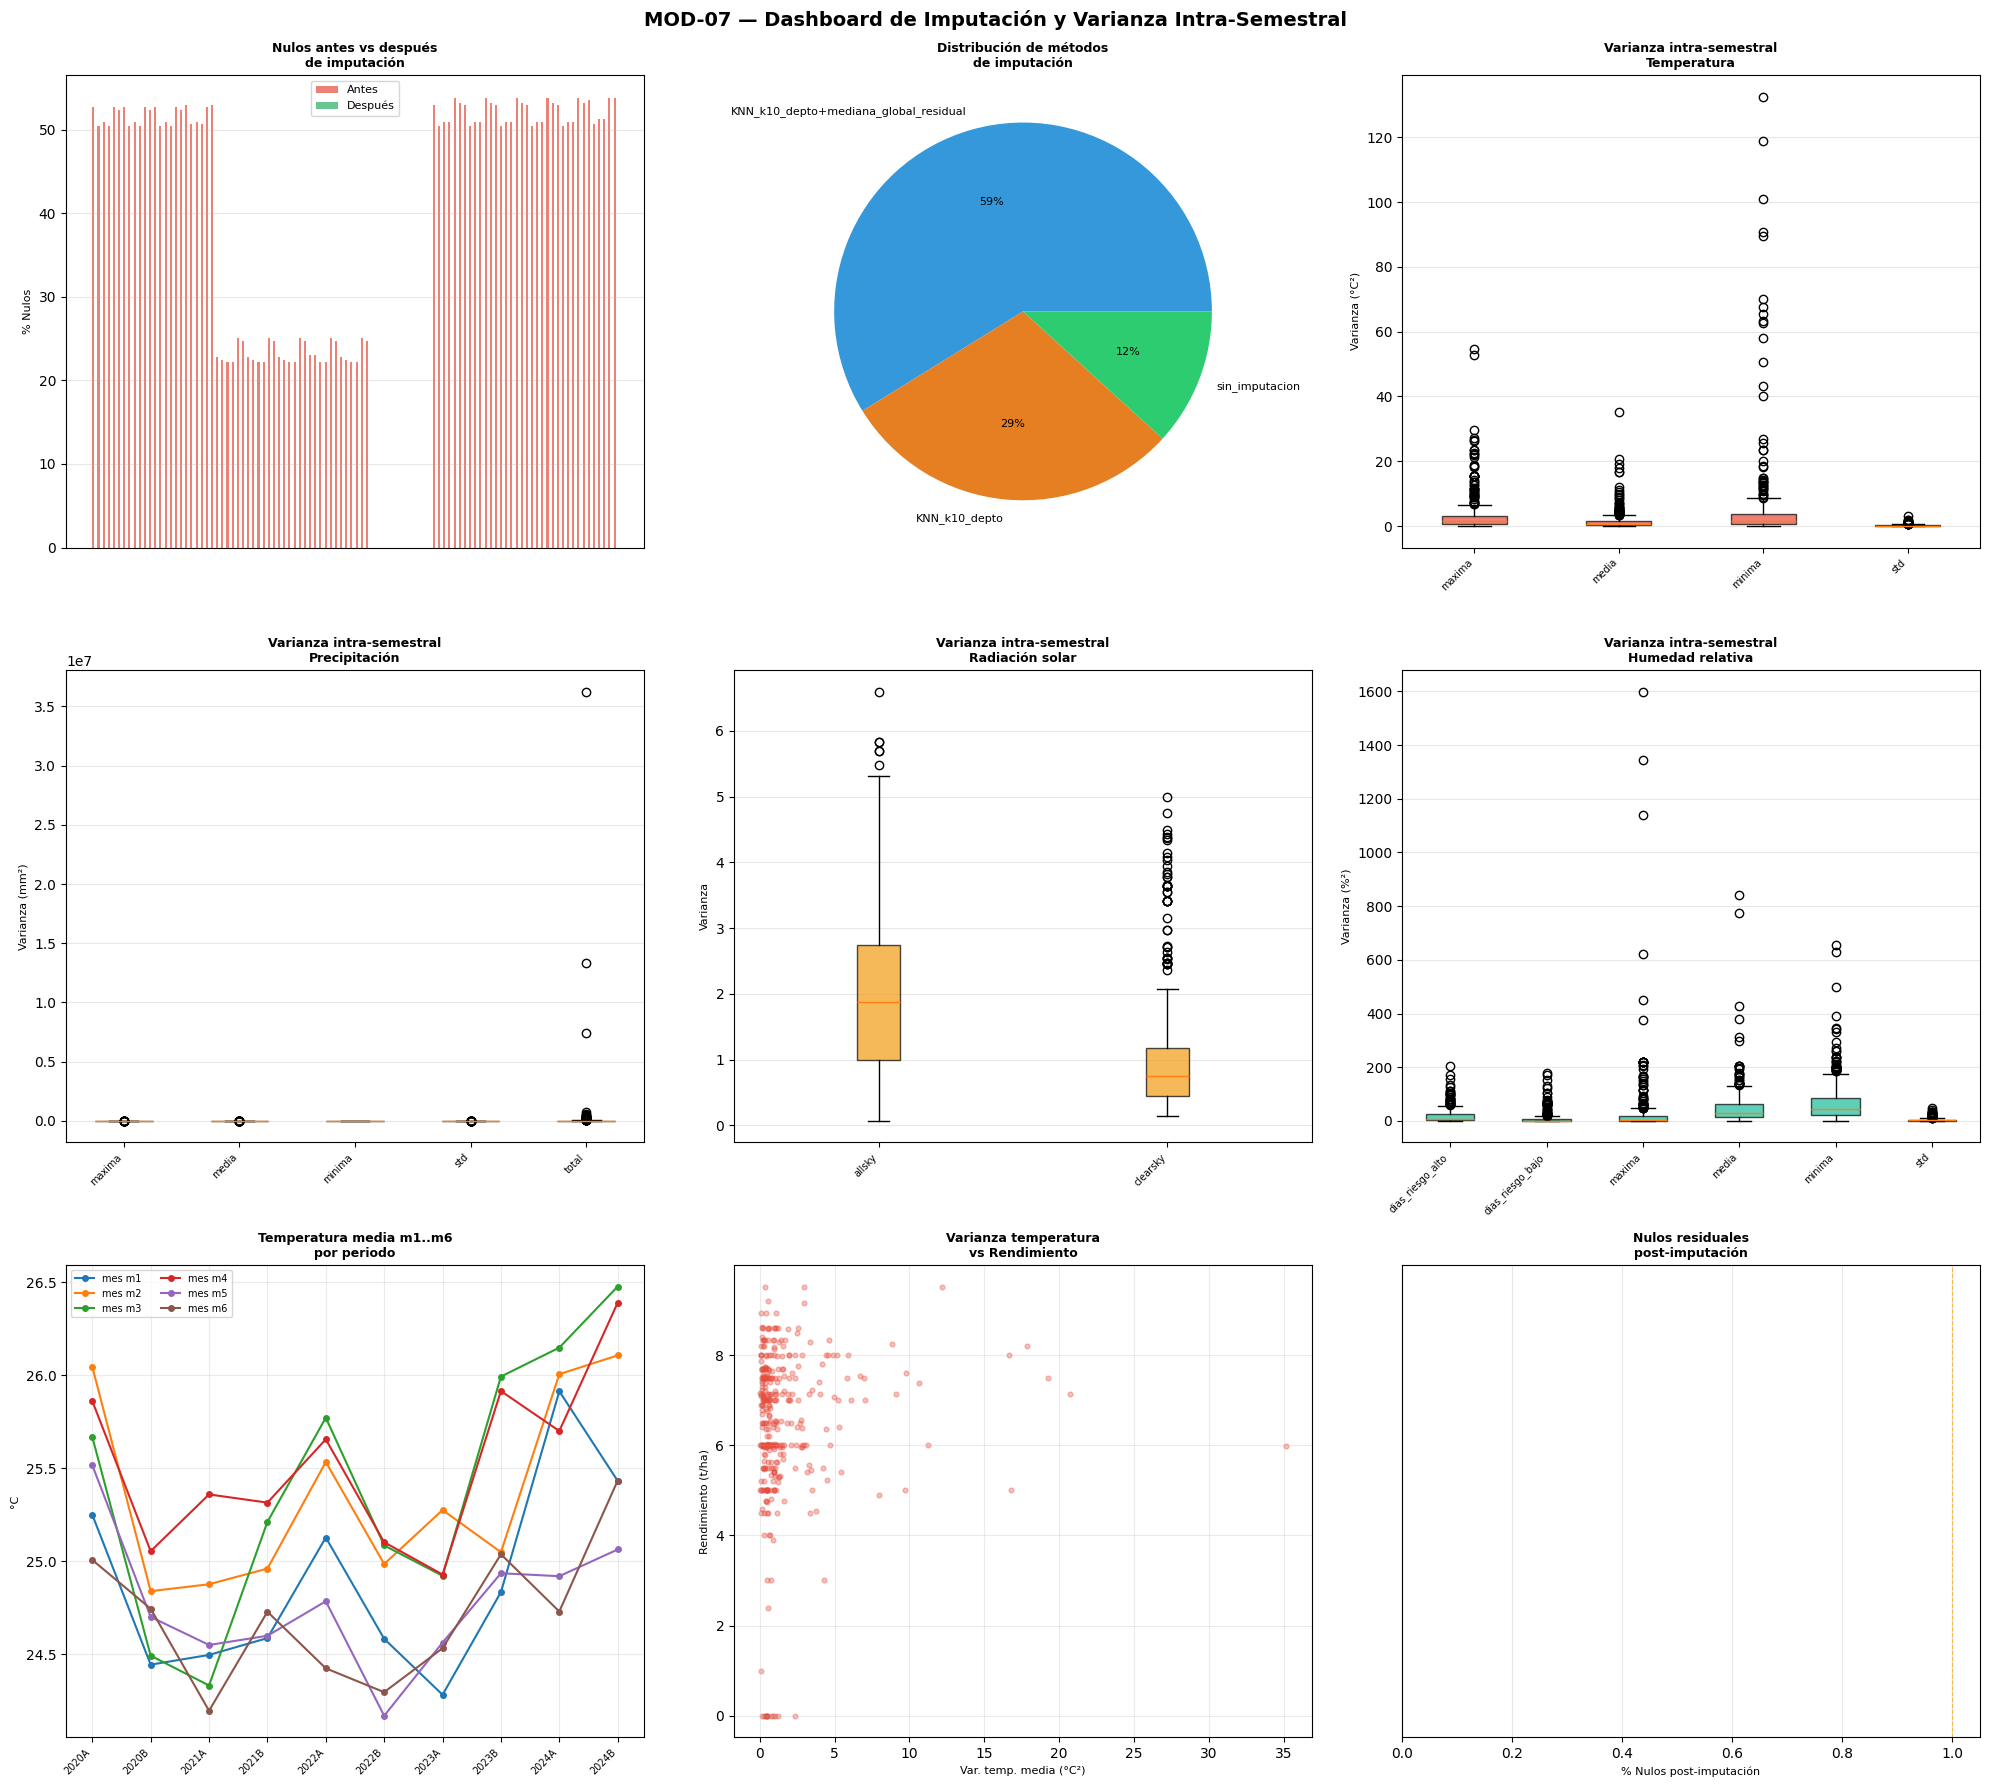

✅ Dashboard guardado: A2_Dashboard_Imputacion.png


In [10]:
# ============================================================
# DASHBOARD — Visualización de imputación y varianzas
# ============================================================

fig = plt.figure(figsize=(20, 18))
fig.suptitle(
    'MOD-07 — Dashboard de Imputación y Varianza Intra-Semestral',
    fontsize=14, fontweight='bold', y=0.99
)

# ── Panel 1: Nulos antes vs después ──────────────────────────
ax1 = fig.add_subplot(3, 3, 1)
cols_comp = [c for c in (COLS_TEMP_F + COLS_PREC_F + COLS_RAD_F + COLS_HR_F)
             if c in df_raw.columns and c in df_imputado.columns]
if cols_comp:
    pct_antes   = df_raw[cols_comp].isna().mean().mul(100)
    pct_despues = df_imputado[cols_comp].isna().mean().mul(100)
    x = range(len(cols_comp))
    ax1.bar(x, pct_antes.values,   width=0.4, label='Antes', color='#e74c3c', alpha=0.7)
    ax1.bar([i+0.4 for i in x], pct_despues.values,
            width=0.4, label='Después', color='#27ae60', alpha=0.7)
    ax1.set_xticks([])
    ax1.set_ylabel('% Nulos', fontsize=8)
    ax1.set_title('Nulos antes vs después\nde imputación', fontsize=9, fontweight='bold')
    ax1.legend(fontsize=8)
    ax1.grid(axis='y', alpha=0.3)

# ── Panel 2: Métodos usados (pastel) ─────────────────────────
ax2 = fig.add_subplot(3, 3, 2)
metodos = {}
for col, info in TRAZA_COMPLETA.items():
    m = info.get('metodo', 'sin_imputacion')
    metodos[m] = metodos.get(m, 0) + 1
if metodos:
    colores_m = ['#3498db','#e67e22','#2ecc71','#e74c3c','#9b59b6']
    ax2.pie(list(metodos.values()), labels=list(metodos.keys()),
            autopct='%1.0f%%', colors=colores_m[:len(metodos)],
            textprops={'fontsize':8})
    ax2.set_title('Distribución de métodos\nde imputación', fontsize=9, fontweight='bold')

# ── Panel 3: Boxplot varianzas de temperatura ────────────────
ax3 = fig.add_subplot(3, 3, 3)
if COLS_VAR_TEMP:
    data_v = [df_imputado[c].dropna().values for c in COLS_VAR_TEMP]
    bp = ax3.boxplot(data_v, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#e74c3c'); patch.set_alpha(0.7)
    ax3.set_xticklabels([c.replace('temperatura_','').replace('_var','')
                         for c in COLS_VAR_TEMP], rotation=45, ha='right', fontsize=7)
    ax3.set_ylabel('Varianza (°C²)', fontsize=8)
    ax3.set_title('Varianza intra-semestral\nTemperatura', fontsize=9, fontweight='bold')
    ax3.grid(axis='y', alpha=0.3)

# ── Panel 4: Boxplot varianzas precipitación ─────────────────
ax4 = fig.add_subplot(3, 3, 4)
if COLS_VAR_PREC:
    data_v = [df_imputado[c].dropna().values for c in COLS_VAR_PREC]
    bp = ax4.boxplot(data_v, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#3498db'); patch.set_alpha(0.7)
    ax4.set_xticklabels([c.replace('precipitacion_','').replace('_var','')
                         for c in COLS_VAR_PREC], rotation=45, ha='right', fontsize=7)
    ax4.set_ylabel('Varianza (mm²)', fontsize=8)
    ax4.set_title('Varianza intra-semestral\nPrecipitación', fontsize=9, fontweight='bold')
    ax4.grid(axis='y', alpha=0.3)

# ── Panel 5: Boxplot varianzas radiación ─────────────────────
ax5 = fig.add_subplot(3, 3, 5)
if COLS_VAR_RAD:
    data_v = [df_imputado[c].dropna().values for c in COLS_VAR_RAD]
    bp = ax5.boxplot(data_v, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#f39c12'); patch.set_alpha(0.7)
    ax5.set_xticklabels([c.replace('radiacion_','').replace('_var','')
                         for c in COLS_VAR_RAD], rotation=45, ha='right', fontsize=7)
    ax5.set_ylabel('Varianza', fontsize=8)
    ax5.set_title('Varianza intra-semestral\nRadiación solar', fontsize=9, fontweight='bold')
    ax5.grid(axis='y', alpha=0.3)

# ── Panel 6: Boxplot varianzas humedad ───────────────────────
ax6 = fig.add_subplot(3, 3, 6)
if COLS_VAR_HR:
    data_v = [df_imputado[c].dropna().values for c in COLS_VAR_HR]
    bp = ax6.boxplot(data_v, patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('#1abc9c'); patch.set_alpha(0.7)
    ax6.set_xticklabels([c.replace('hr_','').replace('_var','')
                         for c in COLS_VAR_HR], rotation=45, ha='right', fontsize=7)
    ax6.set_ylabel('Varianza (%²)', fontsize=8)
    ax6.set_title('Varianza intra-semestral\nHumedad relativa', fontsize=9, fontweight='bold')
    ax6.grid(axis='y', alpha=0.3)

# ── Panel 7: Evolución temperatura media m1..m6 por periodo ──
ax7 = fig.add_subplot(3, 3, 7)
cols_tm = sorted([c for c in COLS_TEMP_F if 'temperatura_media' in c])
if cols_tm and 'Periodo' in df_imputado.columns:
    evo = df_imputado.groupby('Periodo')[cols_tm].mean().reset_index()
    evo = evo.sort_values('Periodo')
    for col in cols_tm:
        lbl = col.replace('temperatura_media_', 'mes ')
        ax7.plot(range(len(evo)), evo[col], marker='o', ms=4, lw=1.5, label=lbl)
    ax7.set_xticks(range(len(evo)))
    ax7.set_xticklabels(evo['Periodo'], rotation=45, ha='right', fontsize=7)
    ax7.set_ylabel('°C', fontsize=8)
    ax7.set_title('Temperatura media m1..m6\npor periodo', fontsize=9, fontweight='bold')
    ax7.legend(fontsize=7, ncol=2)
    ax7.grid(alpha=0.25)

# ── Panel 8: Scatter varianza temp vs Rendimiento ────────────
ax8 = fig.add_subplot(3, 3, 8)
col_var_t  = next((c for c in COLS_VAR_TEMP if 'media' in c), None)
col_rend   = next((c for c in COLS_TARGET_FINAL if 'Rendimiento' in c or
                   'rendimiento' in c), None)
if col_var_t and col_rend and col_var_t in df_imputado.columns:
    sc = df_imputado[[col_var_t, col_rend]].dropna()
    ax8.scatter(sc[col_var_t], sc[col_rend], alpha=0.35, s=12, c='#e74c3c')
    ax8.set_xlabel(f'Var. temp. media (°C²)', fontsize=8)
    ax8.set_ylabel('Rendimiento (t/ha)', fontsize=8)
    ax8.set_title('Varianza temperatura\nvs Rendimiento', fontsize=9, fontweight='bold')
    ax8.grid(alpha=0.25)

# ── Panel 9: Mapa de nulos post-imputación ───────────────────
ax9 = fig.add_subplot(3, 3, 9)
cols_clima_final = (COLS_TEMP_F + COLS_PREC_F + COLS_RAD_F + COLS_HR_F)
cols_clima_pres  = [c for c in cols_clima_final if c in df_imputado.columns]
if cols_clima_pres:
    nulos_post = df_imputado[cols_clima_pres].isna().mean().mul(100)
    ax9.barh(range(len(nulos_post)), nulos_post.values,
             color=['#e74c3c' if v > 5 else '#27ae60' for v in nulos_post.values])
    ax9.set_yticks([])
    ax9.set_xlabel('% Nulos post-imputación', fontsize=8)
    ax9.set_title('Nulos residuales\npost-imputación', fontsize=9, fontweight='bold')
    ax9.axvline(1, color='orange', ls='--', lw=0.8, alpha=0.7)
    ax9.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'A2_Dashboard_Imputacion.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('✅ Dashboard guardado: A2_Dashboard_Imputacion.png')


---
## 💾 CELDA 11 — Reporte de imputación y guardar salidas

Construye reporte de trazabilidad (columna → % nulos original → % final → método → n imputados), lo exporta en Excel con hoja adicional de catálogo de variables `*_var`. Exporta `A2_DF_Imputado.parquet` (Snappy) y `.xlsx` para MOD-08.

In [11]:
# ============================================================
# REPORTE DE IMPUTACIÓN Y GUARDAR SALIDAS
# ============================================================

# ── Reporte de trazabilidad ───────────────────────────────────
df_reporte = construir_reporte_imputacion(
    TRAZA_COMPLETA, df_raw, df_imputado, COLS_EXCLUIDAS
)

print('📋 Reporte de imputación (resumen):')
print(f'   {"Columna":<40}  {"Orig%":>6}  {"Final%":>6}  Método')
print(f'   {"-"*75}')
for _, row in df_reporte.iterrows():
    final_pct = (df_imputado[row["columna"]].isna().mean()*100
                 if row["columna"] in df_imputado.columns else 0)
    print(f'   {row["columna"]:<40}  {row["pct_orig"]:>5.1f}%  '
          f'{final_pct:>5.1f}%  {row["metodo"]}')

# Guardar reporte Excel
with pd.ExcelWriter(SALIDA_REPORTE_XLS, engine='openpyxl') as writer:
    df_reporte.to_excel(writer, sheet_name='Reporte_Imputacion', index=False)

    # Hoja de varianzas
    df_vars = pd.DataFrame({
        'variable_varianza' : VARS_CREADAS,
        'columnas_base'     : [
            ', '.join([f'{v}_m{n}' for n in range(1,7)
                       for v in [col.replace('_var','')]
                       if f'{v}_m{n}' in df_imputado.columns])
            for col in VARS_CREADAS
        ],
        'media_varianza' : [df_imputado[c].mean() if c in df_imputado.columns
                            else None for c in VARS_CREADAS],
        'nulos'          : [df_imputado[c].isna().sum() if c in df_imputado.columns
                            else None for c in VARS_CREADAS],
    })
    df_vars.to_excel(writer, sheet_name='Variables_Varianza', index=False)

print(f'\n✅ Reporte guardado: {SALIDA_REPORTE_XLS}')

# ── Guardar dataset imputado ──────────────────────────────────
print()
print('💾 Guardando A2_DF_Imputado...')
df_imputado.to_parquet(SALIDA_IMPUTADO, index=False,
                        engine='pyarrow', compression='snappy')
print(f'   ✅ Parquet → {SALIDA_IMPUTADO}')
print(f'      {df_imputado.shape[0]:,} filas × {df_imputado.shape[1]} cols')

MAX_EXCEL = 1_048_576
if df_imputado.shape[0] <= MAX_EXCEL:
    df_imputado.to_excel(SALIDA_IMPUTADO_XLS, index=False, engine='openpyxl')
    print(f'   ✅ Excel  → {SALIDA_IMPUTADO_XLS}')
else:
    df_imputado.head(MAX_EXCEL).to_excel(SALIDA_IMPUTADO_XLS, index=False,
                                          engine='openpyxl')
    print(f'   ⚠️  Excel truncado a {MAX_EXCEL:,} filas — usar Parquet en MOD-08')


📋 Reporte de imputación (resumen):
   Columna                                    Orig%  Final%  Método
   ---------------------------------------------------------------------------
   prec_minima_m4                            100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_minima_m3                            100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_minima_m2                            100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_minima_m1                            100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_dias_lluvia_m6                       100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_dias_lluvia_m5                       100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_dias_lluvia_m2                       100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_dias_lluvia_m1                       100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_pct_dias_lluvia_m5                   100.0%    0.0%  EXCLUIDA (100% nulos)
   prec_pct_dias_lluvia_m6                   100.0%    0.0%  EXCLUIDA (

---
## 📋 CELDA 12 — Resumen de ejecución del módulo

Reporta los 4 métodos de imputación aplicados (KNN k=10, eliminación de columna, exclusión total, mediana residual), lista las variables de varianza creadas por bloque con sus columnas fuente e inventario final: filas, columnas, nulos totales residuales.

In [12]:
# ============================================================
# RESUMEN FINAL — MOD-07 v2.0 completado
# ============================================================

sep = '='*65
print(sep)
print('  MOD-07 v2.0 — Imputacion y Control de Calidad  COMPLETADO')
print(sep)

print()
print('Archivos generados:')
for archivo, desc in [
    ('A2_DF_Imputado.parquet',
     str(df_imputado.shape[0]) + ' x ' + str(df_imputado.shape[1]) + ' cols  <- usar en MOD-08'),
    ('A2_DF_Imputado.xlsx',         'inspeccion visual'),
    ('A2_Reporte_Imputacion.xlsx',  'trazabilidad + variables de varianza'),
    ('A2_Dashboard_Imputacion.png', 'dashboard 9 paneles'),
]:
    print(f'   data/master/{archivo}')
    print(f'      {desc}')

print()
print('Metodos de imputacion aplicados v2.0:')
print()
print('  1. KNN k=10 adaptativo por Departamento  [rango: 1% - 80% nulos]')
print('     k_real = min(10, n_validos_en_depto - 1)')
print('     Si depto tiene < 4 filas validas -> mediana del depto')
print('     Nulos residuales post-KNN        -> mediana global')
print()
print('  2. Eliminacion de columna  [rango: > 80% nulos]')
print('     Se eliminan del dataset para no introducir sesgo masivo.')
print()
print('  3. Exclusion total (prec_*)  [100% nulos]')
print('     Indicadores de lluvia excluidos desde el inicio.')
print()
print('  ELIMINADO en v2.0: Mediana Global para rango 51-80%')
print('     Reemplazado por KNN k=10 adaptativo que preserva')
print('     la estructura de correlacion climatica regional.')

print()
print('Inventario final del dataset:')
print(f'   Filas         : {df_imputado.shape[0]:,}')
print(f'   Columnas      : {df_imputado.shape[1]}')
total_nulos = df_imputado.isna().sum().sum()
pct_nulos   = total_nulos / df_imputado.size * 100
print(f'   Nulos totales : {total_nulos:,} ({pct_nulos:.3f}%)')

print()
print('Siguiente modulo: MOD-08 — Ingenieria de Variables')
print('   Entrada: data/master/A2_DF_Imputado.parquet')
print(sep)

print()
print('Vista previa (3 filas):')
cols_prev = (['Periodo','Departamento','Municipio']
             + COLS_TARGET_FINAL[:1]
             + COLS_TEMP_F[:2] + COLS_VAR_TEMP[:1]
             + COLS_PREC_F[:2])
cols_prev = [c for c in cols_prev if c in df_imputado.columns]
display(df_imputado[cols_prev].head(3))


  MOD-07 v2.0 — Imputacion y Control de Calidad  COMPLETADO

Archivos generados:
   data/master/A2_DF_Imputado.parquet
      351 x 143 cols  <- usar en MOD-08
   data/master/A2_DF_Imputado.xlsx
      inspeccion visual
   data/master/A2_Reporte_Imputacion.xlsx
      trazabilidad + variables de varianza
   data/master/A2_Dashboard_Imputacion.png
      dashboard 9 paneles

Metodos de imputacion aplicados v2.0:

  1. KNN k=10 adaptativo por Departamento  [rango: 1% - 80% nulos]
     k_real = min(10, n_validos_en_depto - 1)
     Si depto tiene < 4 filas validas -> mediana del depto
     Nulos residuales post-KNN        -> mediana global

  2. Eliminacion de columna  [rango: > 80% nulos]
     Se eliminan del dataset para no introducir sesgo masivo.

  3. Exclusion total (prec_*)  [100% nulos]
     Indicadores de lluvia excluidos desde el inicio.

  ELIMINADO en v2.0: Mediana Global para rango 51-80%
     Reemplazado por KNN k=10 adaptativo que preserva
     la estructura de correlacion clima

,Periodo,Departamento,Municipio,Área sembrada (ha),temperatura_maxima_m1,temperatura_maxima_m2,temperatura_maxima_var,precipitacion_maxima_m1,precipitacion_maxima_m2
0,2020A,ANTIOQUIA,PUERTO BERRÍO,110.0,33.973854,24.4,15.315477,0.0,0.0
1,2021A,ANTIOQUIA,PUERTO BERRÍO,110.0,33.973854,24.4,15.315477,0.0,0.0
2,2022A,ANTIOQUIA,PUERTO BERRÍO,100.0,33.973854,24.4,15.315477,0.0,0.0
